In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
import torch.optim as optim
import numpy as np
import pandas as pd 
import json

from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score
from medmnist import INFO

from tqdm.notebook import tqdm

from medmnist import ChestMNIST, INFO

from torchvision.models import resnet18

import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
train_df = ChestMNIST(split="train", download=True)
f"{train_df.labels.shape}, {train_df.labels[:5]}"

'(78468, 14), [[0 0 0 0 0 0 0 0 0 0 0 0 0 0]\n [0 0 0 0 0 0 0 0 0 0 0 0 0 0]\n [0 0 0 0 0 0 0 0 0 0 0 0 0 0]\n [0 0 0 0 0 0 0 0 0 0 0 0 0 0]\n [0 0 0 0 0 0 0 0 0 0 0 0 0 0]]'

In [3]:
np.set_printoptions(threshold=np.inf)
print(train_df.labels.sum(axis=1))

[0 0 0 0 0 2 4 1 2 0 0 1 0 1 1 0 0 1 0 0 0 1 0 0 2 2 0 0 2 0 1 1 1 0 0 0 0
 0 2 1 0 0 3 0 3 1 0 1 1 1 0 2 0 0 0 0 2 0 1 2 0 0 4 2 1 0 0 0 0 2 0 1 0 0
 2 1 0 0 4 0 1 1 1 0 3 0 0 0 0 1 0 1 3 0 0 1 0 0 0 0 1 2 1 0 1 0 0 0 3 0 1
 0 0 0 3 0 2 0 3 0 0 2 0 2 1 0 2 0 1 3 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 2
 1 3 0 0 0 0 0 2 2 0 2 0 2 2 0 0 1 0 0 0 1 2 0 1 0 1 1 0 0 1 2 2 0 2 0 1 0
 1 2 0 2 0 1 2 0 0 0 0 1 1 0 1 0 3 0 2 0 0 0 0 1 0 0 2 1 0 0 1 1 0 0 0 4 0
 1 0 1 3 0 0 1 1 1 0 1 0 0 1 1 1 1 2 0 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 0 2 0
 0 2 2 0 0 2 0 2 0 1 1 0 1 0 0 3 0 3 0 2 0 0 0 0 0 0 0 1 1 1 1 2 0 2 0 0 0
 2 0 0 4 0 0 1 1 0 2 0 2 0 0 1 0 3 0 0 2 0 1 0 0 0 0 0 1 1 0 1 3 0 1 0 0 0
 0 2 0 1 1 1 1 0 1 0 0 0 3 3 1 0 0 0 0 2 1 1 0 2 1 0 0 0 2 0 3 1 0 1 2 0 1
 0 0 0 2 3 2 1 2 0 0 0 4 0 0 2 0 0 1 3 2 1 3 0 0 0 1 1 1 1 1 0 2 0 1 1 1 2
 0 2 1 1 0 0 2 1 2 0 0 1 3 1 0 0 0 0 0 0 0 2 0 2 0 0 1 0 0 1 0 2 0 0 0 0 0
 2 0 2 0 1 1 0 1 0 0 0 0 1 0 2 2 0 1 0 2 1 0 0 0 2 2 0 0 2 1 3 2 2 0 0 0 0
 1 1 0 0 0 0 2 2 0 0 0 0 

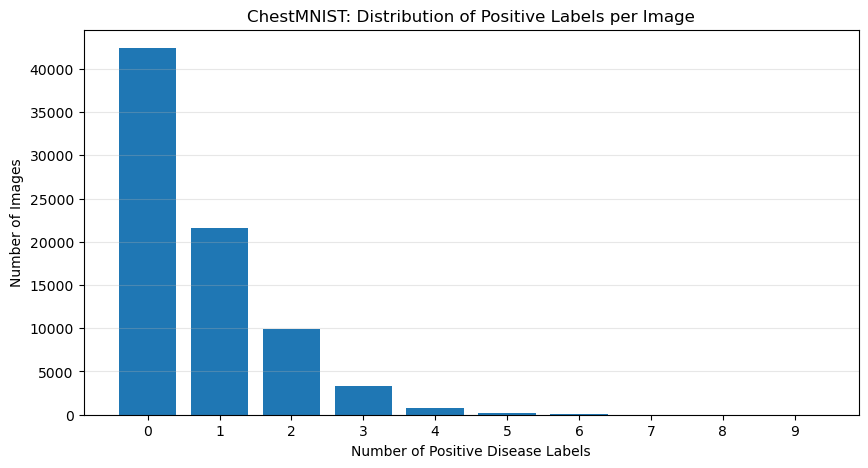

In [4]:
counts = train_df.labels.sum(axis=1)

unique, frequencies = np.unique(counts, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar(unique, frequencies)

plt.xlabel("Number of Positive Disease Labels")
plt.ylabel("Number of Images")
plt.title("ChestMNIST: Distribution of Positive Labels per Image")

plt.xticks(unique)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [5]:
unique

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint64)

In [6]:
frequencies

array([42405, 21602,  9970,  3378,   829,   218,    49,    14,     1,
           2])

In [7]:
class_counts = train_df.labels.sum(axis=0)
class_names = list(INFO["chestmnist"]["label"].values())

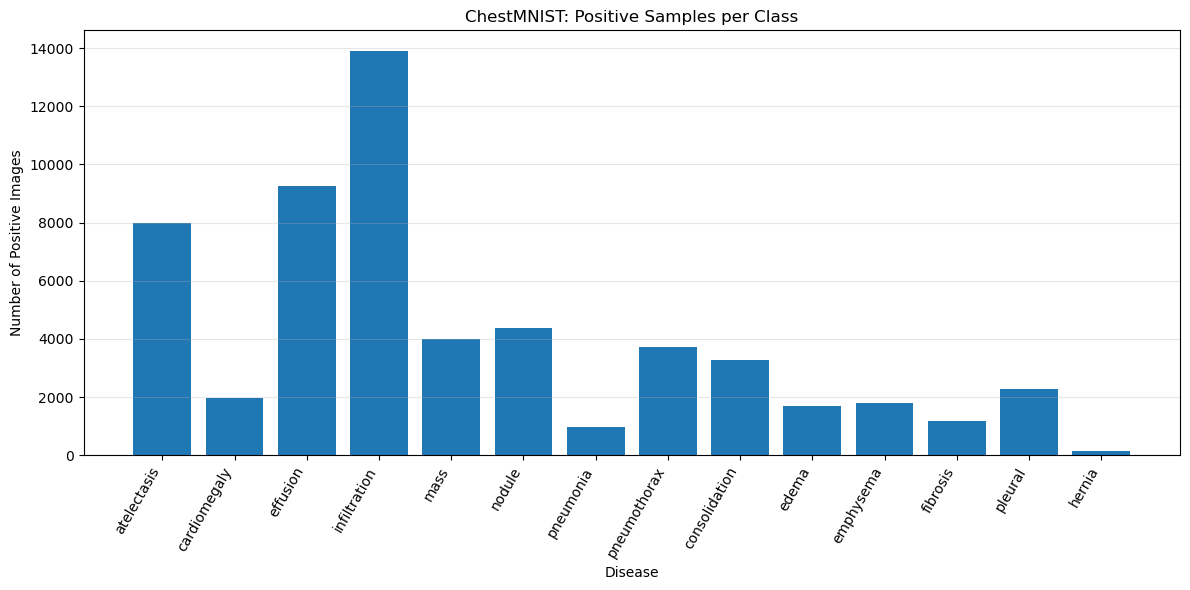

In [8]:
plt.figure(figsize=(12, 6))

plt.bar(class_names, class_counts)

plt.xlabel("Disease")
plt.ylabel("Number of Positive Images")
plt.title("ChestMNIST: Positive Samples per Class")

plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
import torch
import torch.nn as nn
from torchvision.models import resnet18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = resnet18(weights=None)
model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
model.fc = nn.Linear(model.fc.in_features, 14)

model.load_state_dict(
    torch.load("resnet18_chestMNIST.pth", map_location=device, weights_only=True)
)

model = model.to(device)
model.eval()

ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [10]:
torch.cuda.get_device_name()

'NVIDIA GeForce RTX 3050 Laptop GPU'